# Web Crawling dan Analisis PageRank (Web Structure Mining)

**Mata kuliah:** Pencarian & Penambangan Web

Notebook ini membangun sistem yang (1) *meng-crawl* sebuah website dan mengekstraksi tautannya secara berulang,
(2) memodelkan hubungan antarwebsite sebagai **graf berarah**, (3) menghitung **PageRank** dengan *power iteration*,
lalu (4) menentukan website dengan tingkat kepentingan tertinggi. Hasilnya juga tersedia sebagai aplikasi interaktif (`app.py`).

## 1. Landasan Teori: Web Structure Mining & Algoritma PageRank

**Web Structure Mining** menganalisis struktur tautan (*hyperlink*) antarhalaman untuk menemukan pola, misalnya halaman
mana yang menjadi pusat rujukan. Web dimodelkan sebagai graf berarah $G=(V,E)$: tiap halaman/website adalah simpul
(*node*) dan tiap tautan dari A ke B adalah sisi berarah $A \rightarrow B$.

**PageRank** menilai kepentingan sebuah simpul dari banyaknya tautan masuk dan dari seberapa penting simpul yang menautkannya.
Intuisinya: seorang *random surfer* mengikuti tautan secara acak, sesekali melompat ke halaman acak. PageRank adalah
peluang surfer berada di suatu halaman dalam jangka panjang:

$$PR(i) = \frac{1-d}{N} + d \left( \sum_{j \rightarrow i} PR(j)\,\frac{w_{ji}}{W_j} + \frac{1}{N}\sum_{k \in D} PR(k) \right)$$

- $d$ : *damping factor* (umumnya 0,85) — peluang surfer mengikuti tautan.
- $N$ : jumlah simpul.
- $w_{ji}$ : bobot tautan $j \rightarrow i$ (jumlah tautan), $W_j=\sum_i w_{ji}$ : total bobot keluar dari $j$.
- $D$ : simpul *dangling* (tanpa tautan keluar), skornya dibagi rata ke semua simpul.

Nilai PageRank dihitung berulang (**power iteration**) sampai selisih antariterasi sangat kecil (konvergen).

## 2. Persiapan Lingkungan & Pustaka

In [1]:
# Pasang library bila belum ada (hapus tanda # lalu jalankan):
# !pip install requests beautifulsoup4 networkx numpy pandas matplotlib scipy

import time
import re
from collections import Counter, deque, defaultdict
from urllib.parse import urljoin, urldefrag, urlparse
from urllib.robotparser import RobotFileParser

import requests
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from bs4 import BeautifulSoup
from IPython.display import display

pd.set_option("display.float_format", lambda v: f"{v:.5f}")
print("Library siap digunakan.")

Library siap digunakan.


## 3. Implementasi Web Crawler Rekursif (Breadth-First Search)

Crawler memakai antrean **BFS**: halaman seed dikunjungi lebih dulu (kedalaman 0), lalu semua tautannya (kedalaman 1), dan seterusnya
sampai batas kedalaman. Beberapa batasan menjaga crawling tetap sopan dan terkendali:

- batas kedalaman, total halaman, dan halaman per website (agar tidak habis di satu situs),
- jeda antar request dan batas waktu,
- kepatuhan pada `robots.txt`,
- hanya memproses halaman HTML (file gambar, PDF, dsb. dilewati).

In [2]:
HEADERS = {"User-Agent": "PPW-LabCrawler/1.0 (tugas kuliah Pencarian & Penambangan Web)"}
SKIP_EXT = (".pdf", ".jpg", ".jpeg", ".png", ".gif", ".svg", ".webp", ".ico", ".zip", ".rar", ".gz",
            ".mp3", ".mp4", ".avi", ".mov", ".doc", ".docx", ".xls", ".xlsx", ".ppt", ".pptx",
            ".css", ".js", ".xml", ".json")


def normalize_url(url):
    """Buang fragment (#...), rapikan trailing slash, hanya http/https, lewati file non-HTML."""
    if not url:
        return None
    url, _ = urldefrag(url.strip())
    p = urlparse(url)
    if p.scheme not in ("http", "https") or not p.netloc:
        return None
    path = p.path or "/"
    if path != "/" and path.endswith("/"):
        path = path.rstrip("/")
    if path.lower().endswith(SKIP_EXT):
        return None
    return p._replace(netloc=p.netloc.lower(), path=path, fragment="").geturl()


def get_domain(url):
    return urlparse(url).netloc.lower().removeprefix("www.")


_robots = {}
def allowed_by_robots(url, timeout=10):
    p = urlparse(url)
    base = f"{p.scheme}://{p.netloc}"
    if base not in _robots:
        rp = RobotFileParser()
        try:
            r = requests.get(base + "/robots.txt", headers=HEADERS, timeout=timeout)
            rp.parse(r.text.splitlines() if r.status_code == 200 else [])
        except requests.RequestException:
            rp.parse([])
        _robots[base] = rp
    return _robots[base].can_fetch(HEADERS["User-Agent"], url)


def crawl(seed_urls, max_depth=2, max_pages=30, max_per_domain=5, delay=0.5,
          time_limit=60, respect_robots=True, timeout=10, max_links_per_page=150):
    """BFS dari seed. Mengembalikan (pages, edges, errors).
    pages : {url: {title, text, depth}}   edges : {(url_sumber, url_tujuan)}"""
    if isinstance(seed_urls, str):
        seed_urls = [seed_urls]
    seeds = [s for s in (normalize_url(u) for u in seed_urls) if s]
    pages, edges, errors = {}, set(), {}
    queue = deque((s, 0) for s in dict.fromkeys(seeds))
    queued, per_domain, start = set(seeds), Counter(), time.time()

    while queue and len(pages) < max_pages and time.time() - start <= time_limit:
        url, depth = queue.popleft()
        dom = get_domain(url)
        if per_domain[dom] >= max_per_domain:
            continue
        per_domain[dom] += 1
        if respect_robots and not allowed_by_robots(url, timeout):
            errors[url] = "Diblokir robots.txt"
            continue
        try:
            resp = requests.get(url, headers=HEADERS, timeout=timeout)
            if resp.status_code != 200 or "text/html" not in resp.headers.get("Content-Type", ""):
                errors[url] = f"Status {resp.status_code}"
                continue
        except requests.RequestException as e:
            errors[url] = str(e)[:100]
            continue

        soup = BeautifulSoup(resp.text, "html.parser")
        title = soup.title.get_text(strip=True) if soup.title else url
        for tag in soup(["script", "style", "noscript"]):
            tag.decompose()
        pages[url] = {"title": title, "depth": depth,
                      "text": " ".join(soup.get_text(" ", strip=True).split())[:5000]}

        links = []
        for a in soup.find_all("a", href=True):
            t = normalize_url(urljoin(url, a["href"]))
            if t and t != url and t not in links:
                links.append(t)
            if len(links) >= max_links_per_page:
                break
        for t in links:
            edges.add((url, t))
            if depth < max_depth and t not in queued:
                queued.add(t)
                queue.append((t, depth + 1))
        time.sleep(delay)
    return pages, edges, errors

## 4. Eksekusi Crawling pada Website Target

Isi **link website** dan **judul paper** di bawah. Link menjadi titik awal crawling; judul paper dipakai untuk menghitung
skor relevansi tiap website pada tahap analisis.

In [16]:
SEED_URL = "https://en.wikipedia.org/wiki/PageRank"
PAPER_TITLE = "PageRank Algorithm for Web Crawling and Link Structure Analysis"

MAX_DEPTH, MAX_PAGES, MAX_PER_DOMAIN = 2, 30, 5
DELAY, TIME_LIMIT = 0.5, 60
DAMPING = 0.85

t0 = time.time()
pages, page_edges, errors = crawl(SEED_URL, MAX_DEPTH, MAX_PAGES, MAX_PER_DOMAIN, DELAY, TIME_LIMIT)
print(f"Crawling selesai dalam {time.time() - t0:.0f} detik")
print(f"Halaman berhasil di-crawl : {len(pages)}")
print(f"Tautan antarhalaman       : {len(page_edges)}")
print(f"Halaman gagal/dilewati    : {len(errors)}")

Crawling selesai dalam 62 detik
Halaman berhasil di-crawl : 17
Tautan antarhalaman       : 2222
Halaman gagal/dilewati    : 1


In [17]:
# Cadangan agar notebook tetap bisa dijalankan tanpa internet (mis. saat build otomatis).
# Data di bawah adalah DATA CONTOH, bukan hasil crawling sungguhan, dan ditandai DEMO = True.
DEMO = False
if not page_edges:
    DEMO = True
    print("PERINGATAN: crawling tidak menghasilkan data (tidak ada koneksi / situs menolak).")
    print("Notebook memakai DATA CONTOH agar sel berikutnya tetap berjalan. Jalankan ulang dengan internet untuk hasil asli.")
    demo = {
        "kampus.ac.id": ["fakultas.kampus.ac.id", "jurnal.kampus.ac.id", "google.com", "youtube.com", "github.com"],
        "fakultas.kampus.ac.id": ["kampus.ac.id", "jurnal.kampus.ac.id", "google.com"],
        "jurnal.kampus.ac.id": ["kampus.ac.id", "doi.org", "scholar.google.com", "google.com"],
        "doi.org": ["crossref.org"],
        "scholar.google.com": ["google.com"],
        "google.com": ["youtube.com"],
        "youtube.com": ["google.com"],
        "github.com": ["google.com", "docs.github.com"],
        "docs.github.com": ["github.com"],
        "crossref.org": ["doi.org"],
    }
    SEED_URL = "https://kampus.ac.id/"
    page_edges = {(f"https://{s}/", f"https://{d}/p{i}") for s, ds in demo.items() for i, d in enumerate(ds)}
    pages = {f"https://{s}/": {"title": s, "depth": 0,
                               "text": "sistem informasi geografis data stunting balita web" if "jurnal" in s else "beranda website"}
             for s in demo}
print("Mode data:", "DEMO (data contoh)" if DEMO else "crawling sungguhan")

Mode data: crawling sungguhan


In [18]:
sample = pd.DataFrame(sorted(page_edges)[:10], columns=["Halaman sumber", "Halaman tujuan"])
display(sample)

,Halaman sumber,Halaman tujuan
0,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,http://www.google.com/press/funfacts.html
1,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,http://www.tahatek.com/suchmaschinenoptimierun...
2,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
3,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
4,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
5,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
6,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
7,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
8,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...
9,https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%...,https://ar.wikipedia.org/w/index.php?title=%D8...


## 5. Pemodelan Topologi Graf Terarah (*Directed Graph*)

Tautan level halaman digabung menjadi tautan level **website (domain)**. Bobot sisi $w_{ji}$ adalah jumlah tautan dari website $j$
ke website $i$. Tautan ke website sendiri (*self-loop*) dibuang karena tidak menunjukkan pengaruh antarwebsite.

In [19]:
def aggregate_to_domain(page_edges):
    agg = Counter()
    for src, dst in page_edges:
        s, d = get_domain(src), get_domain(dst)
        if s != d:
            agg[(s, d)] += 1
    return agg

edges = aggregate_to_domain(page_edges)        # {(website_asal, website_tujuan): bobot}

G = nx.DiGraph()
for (s, d), w in edges.items():
    G.add_edge(s, d, weight=w)

print(f"Jumlah simpul (website) : {G.number_of_nodes()}")
print(f"Jumlah sisi (tautan)    : {G.number_of_edges()}")
print(f"Kepadatan graf          : {nx.density(G):.4f}")
print(f"Simpul tanpa tautan keluar (dangling): {sum(1 for n in G if G.out_degree(n) == 0)}")

edge_df = (pd.DataFrame([(s, d, w) for (s, d), w in edges.items()], columns=["Sumber", "Tujuan", "Bobot"])
             .sort_values("Bobot", ascending=False).reset_index(drop=True))
display(edge_df.head(10))

Jumlah simpul (website) : 190
Jumlah sisi (tautan)    : 805
Kepadatan graf          : 0.0224
Simpul tanpa tautan keluar (dangling): 176


,Sumber,Tujuan,Bobot
0,eu.wikipedia.org,en.wikipedia.org,10
1,bn.wikipedia.org,foundation.wikimedia.org,6
2,es.wikipedia.org,foundation.wikimedia.org,6
3,ar.wikipedia.org,web.archive.org,5
4,da.wikipedia.org,foundation.wikimedia.org,5
5,eu.wikipedia.org,foundation.wikimedia.org,5
6,donate.wikimedia.org,foundation.wikimedia.org,5
7,az.wikipedia.org,foundation.wikimedia.org,5
8,el.wikipedia.org,foundation.wikimedia.org,5
9,en.wikipedia.org,wikidata.org,5


## 6. Implementasi Algoritma PageRank *From Scratch* (Power Iteration)

Algoritma dibuat sendiri tanpa memanggil `nx.pagerank`. Langkahnya:

1. Semua simpul diberi skor awal $1/N$.
2. Tiap iterasi, setiap simpul membagi skornya ke tetangga tujuan sebanding bobot tautan.
3. Skor simpul *dangling* dibagi rata ke seluruh simpul, lalu ditambah komponen lompatan acak $(1-d)/N$.
4. Ulangi sampai jumlah selisih mutlak antariterasi (norma L1) di bawah toleransi.

In [20]:
def pagerank_scratch(edges, damping=0.85, max_iter=200, tol=1e-10, weighted=True):
    nodes = sorted({n for e in edges for n in e})
    n = len(nodes)
    idx = {node: i for i, node in enumerate(nodes)}

    src = np.array([idx[s] for s, _ in edges])
    dst = np.array([idx[d] for _, d in edges])
    w = np.array([edges[e] if weighted else 1.0 for e in edges], dtype=float)
    out_sum = np.bincount(src, weights=w, minlength=n)      # total bobot keluar tiap simpul
    trans = w / out_sum[src]                                 # peluang berpindah j -> i
    dangling = out_sum == 0

    pr = np.full(n, 1.0 / n)
    history = []
    for it in range(1, max_iter + 1):
        inflow = np.bincount(dst, weights=pr[src] * trans, minlength=n)
        new = damping * (inflow + pr[dangling].sum() / n) + (1 - damping) / n
        delta = np.abs(new - pr).sum()
        history.append(delta)
        pr = new
        if delta < tol:
            break
    return {nodes[i]: float(pr[i]) for i in range(n)}, history

scores, history = pagerank_scratch(edges, damping=DAMPING)
print(f"Konvergen dalam {len(history)} iterasi")
print(f"Jumlah seluruh skor PageRank = {sum(scores.values()):.6f}  (harus 1)")

Konvergen dalam 11 iterasi
Jumlah seluruh skor PageRank = 1.000000  (harus 1)


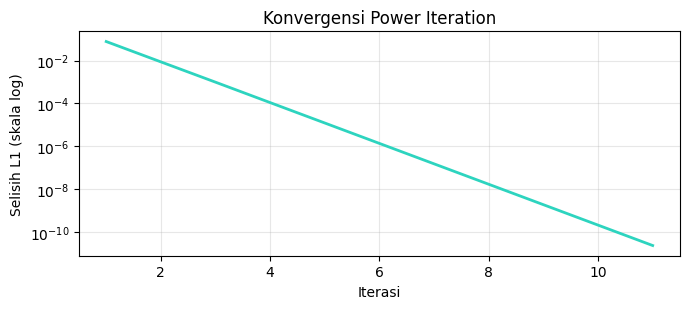

In [21]:
plt.figure(figsize=(7, 3.2))
plt.semilogy(range(1, len(history) + 1), history, color="#2dd4bf", lw=2)
plt.xlabel("Iterasi"); plt.ylabel("Selisih L1 (skala log)")
plt.title("Konvergensi Power Iteration"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Validasi dan Komparasi dengan NetworkX

Hasil implementasi sendiri dibandingkan dengan `networkx.pagerank` memakai parameter yang sama
(damping dan bobot sisi). Selisih yang sangat kecil menunjukkan implementasi sudah benar.

In [22]:
nx_scores = nx.pagerank(G, alpha=DAMPING, weight="weight", tol=1e-12, max_iter=1000)

compare = pd.DataFrame({"Scratch": pd.Series(scores), "NetworkX": pd.Series(nx_scores)})
compare["Selisih"] = (compare["Scratch"] - compare["NetworkX"]).abs()
compare = compare.sort_values("Scratch", ascending=False)
display(compare.head(10))

max_diff = compare["Selisih"].max()
print(f"Selisih maksimum  : {max_diff:.2e}")
print("Urutan 10 teratas sama:", list(compare.index[:10]) == sorted(nx_scores, key=nx_scores.get, reverse=True)[:10])
assert max_diff < 1e-6, "Implementasi menyimpang dari NetworkX"

,Scratch,NetworkX,Selisih
foundation.wikimedia.org,0.00977,0.00977,0.00000
en.wikipedia.org,0.00769,0.00769,0.00000
commons.wikimedia.org,0.00649,0.00649,0.00000
mediawiki.org,0.00640,0.00640,0.00000
wikidata.org,0.00635,0.00635,0.00000
web.archive.org,0.00633,0.00633,0.00000
donate.wikimedia.org,0.00602,0.00602,0.00000
id.wikipedia.org,0.00599,0.00599,0.00000
ko.wikipedia.org,0.00599,0.00599,0.00000
kk.wikipedia.org,0.00599,0.00599,0.00000


Selisih maksimum  : 1.73e-17
Urutan 10 teratas sama: False


## 8. Visualisasi Graf Jaringan Web

Ukuran dan warna simpul mengikuti PageRank (biru-hijau = rendah, kuning = tinggi). Website awal diberi warna koral.
Ketebalan garis menunjukkan jumlah tautan, dan panah menunjukkan arah tautan.

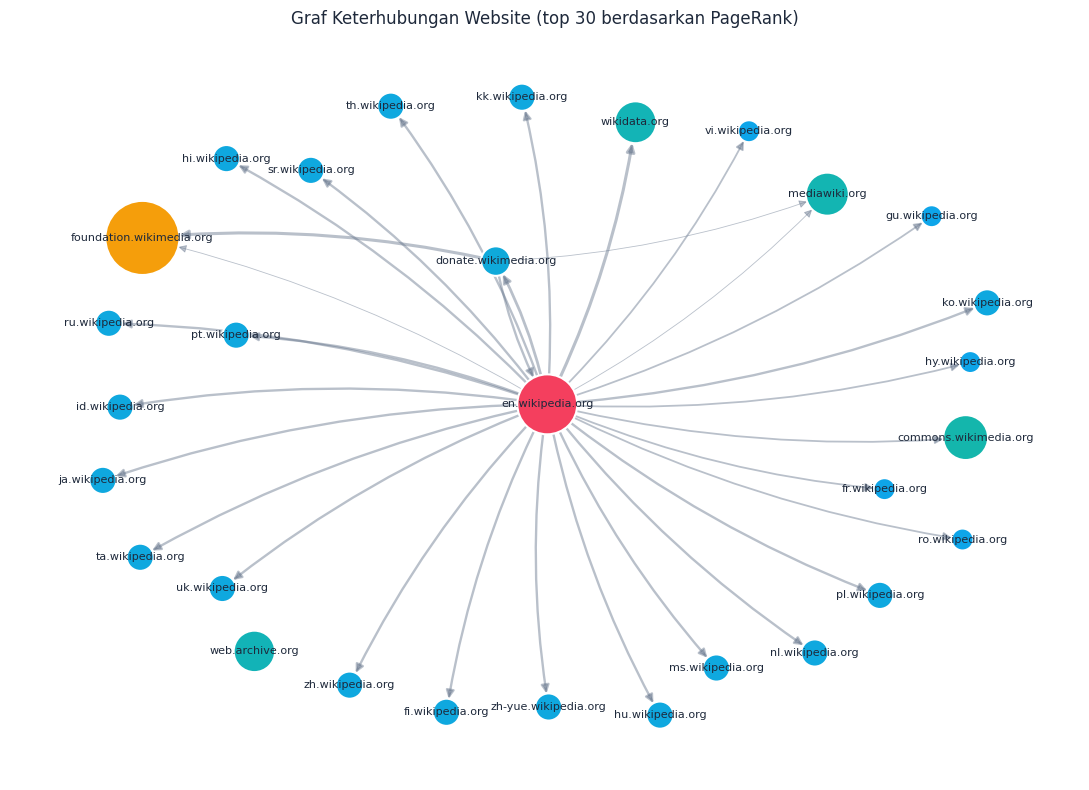

In [28]:
def draw_graph(G, scores, seed_domain=None, top_n=30, figsize=(11, 8)):
    top = sorted(scores, key=scores.get, reverse=True)[:top_n]
    keep = set(top) | ({seed_domain} if seed_domain in G else set())
    H = G.subgraph(keep)
    vals = np.array([scores[n] for n in H.nodes])
    t = (vals - vals.min()) / (vals.max() - vals.min() + 1e-12)
    t = t ** 0.6

    # warna sedikit lebih tua agar jelas di latar putih
    cmap = LinearSegmentedColormap.from_list("aurora_light", ["#0ea5e9", "#14b8a6", "#84cc16", "#f59e0b"])
    colors = [cmap(v) for v in t]
    colors = ["#f43f5e" if n == seed_domain else c for n, c in zip(H.nodes, colors)]
    sizes = 250 + 2600 * t
    widths = [min(0.6 + np.log(H[u][v]["weight"]), 4) for u, v in H.edges]

    pos = nx.spring_layout(H, k=1.2 / np.sqrt(max(len(H), 1)), seed=42, weight=None)
    fig, ax = plt.subplots(figsize=figsize, facecolor="white")
    ax.set_facecolor("white")
    nx.draw_networkx_edges(H, pos, ax=ax, width=widths, edge_color="#64748b", alpha=.45,
                           arrows=True, arrowsize=12, connectionstyle="arc3,rad=0.08",
                           node_size=sizes)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=colors,
                           edgecolors="white", linewidths=1.5)
    labels = {n: (n if len(n) <= 24 else n[:21] + "...") for n in H.nodes}
    nx.draw_networkx_labels(H, pos, labels, ax=ax, font_size=8, font_color="#1e293b")
    ax.set_title(f"Graf Keterhubungan Website (top {len(H)} berdasarkan PageRank)",
                 color="#1e293b", fontsize=12)
    ax.axis("off")
    plt.tight_layout(); plt.show()

seed_domain = get_domain(SEED_URL)
draw_graph(G, scores, seed_domain)

## 9. Analisis Hasil & Peringkat Website Terpenting

Tabel peringkat memuat skor PageRank, jumlah tautan masuk/keluar, dan **skor relevansi judul paper**
(proporsi kata kunci judul yang muncul pada teks halaman website tersebut).

In [29]:
STOPWORDS = {"the", "of", "and", "a", "an", "in", "on", "for", "to", "with", "by", "using", "based",
             "yang", "dan", "di", "ke", "dari", "untuk", "pada", "dengan", "atau", "sebuah", "analisis"}

def tokens(text):
    return {t for t in re.findall(r"[a-zA-Z0-9]+", text.lower()) if t not in STOPWORDS and len(t) > 2}

domain_text = defaultdict(str)
for url, info in pages.items():
    domain_text[get_domain(url)] += f" {info['title']} {info['text']}"

query = tokens(PAPER_TITLE)
def relevance(domain):
    if not query or domain not in domain_text:
        return np.nan
    return round(len(query & tokens(domain_text[domain])) / len(query), 3)

crawled = Counter(get_domain(u) for u in pages)
ranking = pd.DataFrame({
    "Website": list(scores),
    "PageRank": [scores[n] for n in scores],
    "Tautan masuk": [G.in_degree(n) for n in scores],
    "Tautan keluar": [G.out_degree(n) for n in scores],
    "Halaman di-crawl": [crawled.get(n, 0) for n in scores],
    "Relevansi judul": [relevance(n) for n in scores],
}).sort_values("PageRank", ascending=False).reset_index(drop=True)
ranking.index += 1
ranking.index.name = "Peringkat"
display(ranking.head(15))

,Website,PageRank,Tautan masuk,Tautan keluar,Halaman di-crawl,Relevansi judul
Peringkat,,,,,,
1,foundation.wikimedia.org,0.00977,9,0,0,NaN
2,en.wikipedia.org,0.00769,13,157,4,0.85700
3,commons.wikimedia.org,0.00649,13,0,0,NaN
4,mediawiki.org,0.00640,9,0,0,NaN
5,wikidata.org,0.00635,13,0,0,NaN
6,web.archive.org,0.00633,8,0,0,NaN
7,donate.wikimedia.org,0.00602,13,7,1,0.00000
8,id.wikipedia.org,0.00599,13,0,0,NaN
9,ko.wikipedia.org,0.00599,13,0,0,NaN


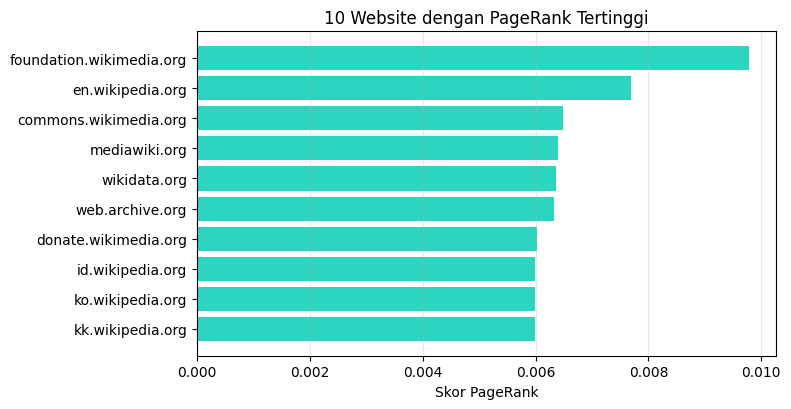

In [26]:
top10 = ranking.head(10).iloc[::-1]
plt.figure(figsize=(8, 4.2))
plt.barh(top10["Website"], top10["PageRank"], color="#2dd4bf")
plt.xlabel("Skor PageRank"); plt.title("10 Website dengan PageRank Tertinggi")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

In [27]:
best = ranking.iloc[0]
print("Mode data       :", "DEMO (data contoh)" if DEMO else "hasil crawling sungguhan")
print(f"Website terpenting: {best['Website']}  (PageRank = {best['PageRank']:.5f})")
print(f"  - tautan masuk dari {int(best['Tautan masuk'])} website, tautan keluar ke {int(best['Tautan keluar'])} website")

if query:
    rel = ranking.dropna(subset=["Relevansi judul"]).sort_values(["Relevansi judul", "PageRank"], ascending=False)
    rel = rel[rel["Relevansi judul"] > 0].head(5)
    print("\nWebsite paling relevan dengan judul paper:")
    display(rel[["Website", "Relevansi judul", "PageRank"]] if len(rel) else pd.DataFrame())

Mode data       : hasil crawling sungguhan
Website terpenting: foundation.wikimedia.org  (PageRank = 0.00977)
  - tautan masuk dari 9 website, tautan keluar ke 0 website

Website paling relevan dengan judul paper:


,Website,Relevansi judul,PageRank
Peringkat,,,
2,en.wikipedia.org,0.85700,0.00769
40,ar.wikipedia.org,0.71400,0.00591
48,de.wikipedia.org,0.42900,0.00586
39,es.wikipedia.org,0.28600,0.00592
41,eu.wikipedia.org,0.28600,0.00590


### Kesimpulan

*(Tulis kesimpulan dengan kalimat Anda sendiri setelah menjalankan notebook dengan data sungguhan, misalnya: website mana yang
paling penting, mengapa website itu mendapat PageRank tertinggi (banyak tautan masuk atau dirujuk website penting), dan apakah
website tersebut relevan dengan judul paper.)*

## 10. Persiapan dan Deployment Aplikasi Interaktif (`app.py`)

Seluruh alur di atas dikemas menjadi aplikasi web berbasis **Streamlit**: pengguna mengisi link website dan/atau judul paper,
lalu aplikasi menampilkan graf interaktif, peringkat PageRank, website terkait, dan tombol unduh hasil.

Struktur berkas aplikasi (folder `pagerank_crawler/`):

| Berkas | Fungsi |
|---|---|
| `app.py` | Antarmuka dan pengendali alur |
| `search.py` | Mencari website awal dari judul paper |
| `crawler.py` | Crawler BFS |
| `pagerank_utils.py` | PageRank, tabel peringkat, relevansi |
| `visualizer.py` | Graf interaktif (pyvis) |
| `requirements.txt` | Daftar dependensi |
| `.streamlit/config.toml` | Tema tampilan |

### Cara Menjalankan Aplikasi di Lokal

Windows (PowerShell), dari folder `pagerank_crawler`:

```powershell
python -m venv .venv-crawler
.\.venv-crawler\Scripts\Activate.ps1
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

Aplikasi terbuka di `http://localhost:8501`.

### Cara Menjalankan Aplikasi di Server Warga Laboratorium

Linux, dari folder `pagerank_crawler`:

```bash
git clone <alamat-repo-github>
cd <nama-repo>/pagerank_crawler
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
nohup python -m streamlit run app.py --server.address 0.0.0.0 --server.port 8501 > app.log 2>&1 &
```

Aplikasi dapat dibuka di `http://<IP-server>:8501`. Hal yang perlu dipastikan dengan admin lab: versi Python 3.9 ke atas,
server dapat mengakses internet (untuk crawling), port 8501 terbuka, dan, bila ingin berjalan permanen, dijalankan sebagai
layanan `systemd` atau di dalam `tmux`/`screen`.